In [1]:
#import required library
import requests
from bs4 import BeautifulSoup
import pandas as pd

In [2]:
# Website URL
url = "http://books.toscrape.com/"
# Send HTTP request
response = requests.get(url)

#confirm the request was succesful
if response.status_code != 200:
    print("Failed to retrieve webpage")
    exit()

In [3]:
# Parse HTML and extract html
htmlParsed = BeautifulSoup(response.text, "html.parser")

# Extract All Books table
books = htmlParsed.find_all("article", class_="product_pod")

# Store extracted data
data = []


In [4]:
print(books)

[<article class="product_pod">
<div class="image_container">
<a href="catalogue/a-light-in-the-attic_1000/index.html"><img alt="A Light in the Attic" class="thumbnail" src="media/cache/2c/da/2cdad67c44b002e7ead0cc35693c0e8b.jpg"/></a>
</div>
<p class="star-rating Three">
<i class="icon-star"></i>
<i class="icon-star"></i>
<i class="icon-star"></i>
<i class="icon-star"></i>
<i class="icon-star"></i>
</p>
<h3><a href="catalogue/a-light-in-the-attic_1000/index.html" title="A Light in the Attic">A Light in the ...</a></h3>
<div class="product_price">
<p class="price_color">Â£51.77</p>
<p class="instock availability">
<i class="icon-ok"></i>
    
        In stock
    
</p>
<form>
<button class="btn btn-primary btn-block" data-loading-text="Adding..." type="submit">Add to basket</button>
</form>
</div>
</article>, <article class="product_pod">
<div class="image_container">
<a href="catalogue/tipping-the-velvet_999/index.html"><img alt="Tipping the Velvet" class="thumbnail" src="media/cache/2

In [5]:
for book in books:

    # Title
    title = book.h3.a["title"]

    # Price
    price = book.find("p", class_="price_color").text.strip()

    # Rating
    rating_class = book.find("p", class_="star-rating")["class"][1]

    # Availability
    availability = book.find("p", class_="instock availability").text.strip()

    data.append({
        "Title": title,
        "Price": price,
        "Rating": rating_class,
        "Availability": availability
    })

df = pd.DataFrame(data)
df.head()

,Title,Price,Rating,Availability
0,A Light in the Attic,Â£51.77,Three,In stock
1,Tipping the Velvet,Â£53.74,One,In stock
2,Soumission,Â£50.10,One,In stock
3,Sharp Objects,Â£47.82,Four,In stock
4,Sapiens: A Brief History of Humankind,Â£54.23,Five,In stock


In [6]:
#Evaluate the structire of the frame
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 20 entries, 0 to 19
Data columns (total 4 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   Title         20 non-null     str  
 1   Price         20 non-null     str  
 2   Rating        20 non-null     str  
 3   Availability  20 non-null     str  
dtypes: str(4)
memory usage: 772.0 bytes


In [7]:
#Deterine the uniqness of the Rating Data
df.Rating.value_counts()

Rating
One      6
Four     4
Five     4
Three    3
Two      3
Name: count, dtype: int64

In [8]:
df.Availability.value_counts()

Availability
In stock    20
Name: count, dtype: int64

In [9]:
# Rating mapping
rating_maps = {
    "One": 1,
    "Two": 2,
    "Three": 3,
    "Four": 4,
    "Five": 5
}

# Remove £ symbol and convert to float
df["Price"] = (
    df["Price"]
      .str.replace("£", "", regex=False)
      .str.replace("Â", "", regex=False)
      .astype(float)
)

# Convert ratings to numbers
df["Rating"] = df["Rating"].str.strip().map(rating_maps)

In [10]:
df.Rating.value_counts()

Rating
1    6
4    4
5    4
3    3
2    3
Name: count, dtype: int64

In [11]:
df.head(15)

,Title,Price,Rating,Availability
0,A Light in the Attic,51.77,3,In stock
1,Tipping the Velvet,53.74,1,In stock
2,Soumission,50.10,1,In stock
3,Sharp Objects,47.82,4,In stock
4,Sapiens: A Brief History of Humankind,54.23,5,In stock
5,The Requiem Red,22.65,1,In stock
6,The Dirty Little Secrets of Getting Your Dream...,33.34,4,In stock
7,The Coming Woman: A Novel Based on the Life of...,17.93,3,In stock
8,The Boys in the Boat: Nine Americans and Their...,22.60,4,In stock
9,The Black Maria,52.15,1,In stock


In [12]:
df.info()
df[df.Rating.isna()]
# df['column_name'] = df['column_name'].astype(int)
# df['Rating'].astype(int).groupby("Category")["Rating"].mean()

<class 'pandas.DataFrame'>
RangeIndex: 20 entries, 0 to 19
Data columns (total 4 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Title         20 non-null     str    
 1   Price         20 non-null     float64
 2   Rating        20 non-null     int64  
 3   Availability  20 non-null     str    
dtypes: float64(1), int64(1), str(2)
memory usage: 772.0 bytes


,Title,Price,Rating,Availability


In [13]:
# Convert ratings to numbers
# df["Rating"] = df["Rating"].str.strip().map(rating_maps)

df["Category"] = df["Price"].apply(
    lambda x: "Affordable" if x < 20 else "Expensive"
)
# Average rating by category
average_ratings = df.groupby("Category")["Rating"].mean()
# average_ratings = df.groupby("Category")["Rating"]
# average_ratings.head()
average_ratings

# df.head()

Category
Affordable    3.333333
Expensive     2.764706
Name: Rating, dtype: float64

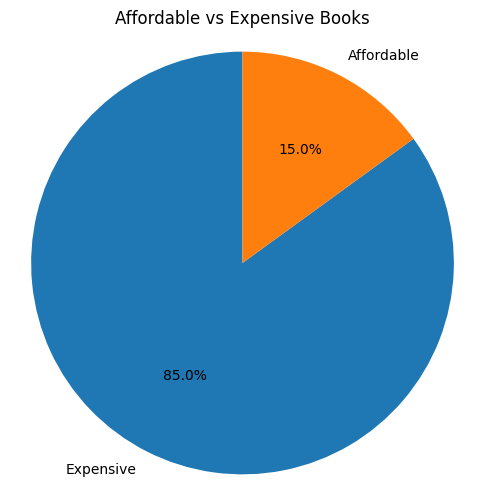

In [14]:
import matplotlib.pyplot as plt 
category_counts = df["Category"].value_counts()

plt.figure(figsize=(6,6))
plt.pie(
    category_counts,
    labels=category_counts.index,
    autopct="%1.1f%%",
    startangle=90
)
plt.title("Affordable vs Expensive Books")
plt.axis("equal")
plt.show()

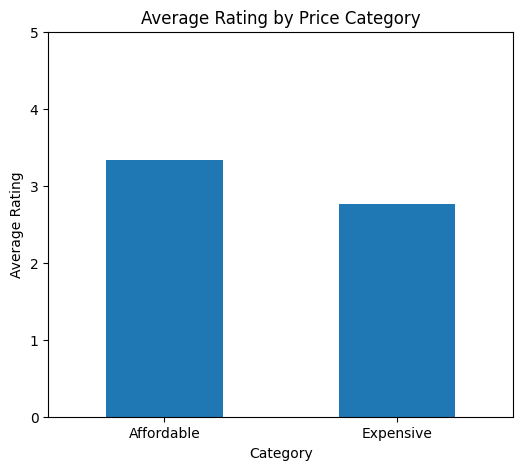

In [15]:
plt.figure(figsize=(6,5))
average_ratings.plot(kind="bar")

plt.title("Average Rating by Price Category")
plt.xlabel("Category")
plt.ylabel("Average Rating")
plt.xticks(rotation=0)
plt.ylim(0,5)

plt.show()

In [16]:
df.to_csv("book_data.csv", index=False)